# Solutions to the exercises of Chapter 6

Sample solutions for [Chapter 6, Capillary rise and imbibition](../../notebooks/part2_liquids_interfaces/06_capillary_rise.ipynb).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.integrate import solve_ivp

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

## Exercise 1. Between two plates

Take a unit width of the plates. The liquid wets two walls, so the free energy has
the wetting term $-2\gamma\cos\theta\,h$; the column has cross-section $2b$, so its
gravitational energy is $\tfrac12\rho g\,(2b)\,h^2$:

$$ A = -2\gamma\cos\theta\,h + \rho g b\,h^2 . $$

The flow is between two walls a distance $2b$ apart. The second table of
Section 3.2 gives a friction $12\eta/(2b)$ per unit area of the plates, over the wetted
area $h$:

$$ \Phi = \tfrac12\,\frac{6\eta}{b}\,h\,\dot h^2 . $$

Minimising: $(6\eta/b)\,h\dot h = 2\gamma\cos\theta - 2\rho g b\,h$. Hence

$$ h_J = \frac{\gamma\cos\theta}{\rho g b} , \qquad h^2 = \frac{2b\gamma\cos\theta}{3\eta}\,t \quad (h \ll h_J) . $$

Compared with a tube of radius $b$, the plates raise the liquid to half the height
(one curved direction instead of two) but faster at first, by a factor $4/3$ in
$h^2/t$: the flow between plates meets less friction per unit of driving force.

In [2]:
h, hdot = sp.symbols("h hdot")
gam, ct, rho, g, b, eta = sp.symbols("gamma cos_theta rho g b eta", positive=True)
A = -2 * gam * ct * h + rho * g * b * h**2
Phi = sp.Rational(1, 2) * (12 * eta / (2 * b)) * h * hdot**2
eq = on.kinetic_equations(A, Phi, [h], [hdot])
print("hdot =", sp.factor(eq[hdot]))
print("Jurin height:", sp.solve(eq[hdot], h))
print("early times, h hdot =", sp.simplify(sp.limit(h * eq[hdot], h, 0)), "  so  h^2/t =", sp.simplify(2 * sp.limit(h * eq[hdot], h, 0)))
tube = 2 * b * gam * ct / (4 * eta)          # h^2/t for a tube of radius b, Eq. (6.5)
print("ratio of h^2/t, plates / tube of radius b:", sp.simplify(2 * sp.limit(h * eq[hdot], h, 0) / tube))

hdot = -b*(b*g*h*rho - cos_theta*gamma)/(3*eta*h)
Jurin height: [cos_theta*gamma/(b*g*rho)]
early times, h hdot = b*cos_theta*gamma/(3*eta)   so  h^2/t = 2*b*cos_theta*gamma/(3*eta)
ratio of h^2/t, plates / tube of radius b: 4/3


## Exercise 2. A bundle of tubes

With $n$ tubes of radius $a$ per unit cross-section:

* porosity $\phi = n\pi a^2$;
* Poiseuille's law gives a flow rate $\pi a^4 G/8\eta$ per tube under a pressure gradient
  $G$, so the superficial velocity is $q = n\pi a^4G/8\eta$, and Darcy's law $q = \kappa G/\eta$
  gives $\kappa = n\pi a^4/8$;
* the capillary pressure is that of one meniscus, $p_c = 2\gamma\cos\theta/a$.

Then

$$ \frac{2\kappa p_c}{\eta\phi} = \frac{2\,(n\pi a^4/8)\,(2\gamma\cos\theta/a)}{\eta\,n\pi a^2} = \frac{a\gamma\cos\theta}{2\eta} , $$

which is the coefficient of Eq. (6.5): the porous-medium law and the single-tube law
agree, as they must for a medium that is a bundle of identical tubes.

With tubes of two radii, $a$ and $2a$, each tube fills independently (the tubes are
not connected), $L_i^2 = a_i\gamma\cos\theta\,t/2\eta$. The wider tubes fill faster, by a
factor $\sqrt2$ in length. The total volume taken up,
$V = \sum_i n_i\pi a_i^2L_i \propto \sqrt t$, is still a Lucas–Washburn law, with an
effective radius that is a weighted mean of the two. The cell checks this. In real
porous materials the pores are connected, liquid can pass from wide pores to narrow
ones, and the effective radius obtained from $V^2/t$ is not simply a property of the
pore-size distribution; that is one reason why Washburn measurements of porous
materials need care.

In [3]:
gamma_, eta_, a_ = 0.072, 1e-3, 1e-5                        # water, tubes of radius 10 and 20 micrometres
t = np.logspace(-3, 1, 50)
L1 = np.sqrt(a_ * gamma_ * t / (2 * eta_))
L2 = np.sqrt(2 * a_ * gamma_ * t / (2 * eta_))
V = math.pi * a_**2 * L1 + math.pi * (2 * a_) ** 2 * L2      # one tube of each kind
slope, _ = on.loglog_slope(t, V)
print(f"L(2a)/L(a) = {L2[0] / L1[0]:.4f}  (sqrt 2 = {math.sqrt(2):.4f})")
print(f"total uptake V ~ t^{slope:.4f}")
a_eff = (V[-1] / (math.pi * 5 * a_**2)) ** 2 * 2 * eta_ / (gamma_ * t[-1])   # V = phi_total * sqrt(a_eff gamma t / 2 eta)
print(f"effective radius from V^2/t: {a_eff / a_:.3f} a")

L(2a)/L(a) = 1.4142  (sqrt 2 = 1.4142)
total uptake V ~ t^0.5000
effective radius from V^2/t: 1.773 a


## Exercise 3. Oscillations

With $H = 1 + \delta$ and $\delta$ small, $H\,dH/dT \approx d\delta/dT$, and Eq. (6.8) becomes

$$ \varepsilon\,\delta'' + \delta' + \delta = 0 . $$

Trying $\delta = e^{sT}$: $\varepsilon s^2 + s + 1 = 0$, so
$s = [-1 \pm \sqrt{1 - 4\varepsilon}]/2\varepsilon$. The roots are complex, and the column
oscillates, when $\varepsilon > \tfrac14$; then

$$ s = -\frac{1}{2\varepsilon} \pm i\omega , \qquad \omega = \frac{\sqrt{4\varepsilon - 1}}{2\varepsilon} . $$

For $\varepsilon = 28$, $\omega = 0.188$ and the period is $2\pi/\omega = 33.4$ in units of
$\tau$. The cell measures the period of the late, small oscillations of the
numerical solution, where the linearisation applies. For ether in the tube of
radius 0.689 mm, $\tau = 8\eta h_J/\rho g a^2 = 5.0$ ms, so the period is about 0.17 s.

In [4]:
def bosanquet(eps, T):
    rhs = lambda t, y: [y[1], (2 * (1 - np.sqrt(max(y[0], 0.0))) - y[1]) / eps]
    sol = solve_ivp(rhs, (0, T[-1]), [0.0, 0.0], t_eval=T, rtol=1e-11, atol=1e-13, method="LSODA")
    return np.sqrt(np.maximum(sol.y[0], 0.0))


eps = 28.0
T = np.linspace(0, 400, 400001)
H = bosanquet(eps, T)
d = H - 1
up = np.where((d[:-1] < 0) & (d[1:] >= 0))[0]                 # upward zero crossings
T_up = T[up] - d[up] * (T[up + 1] - T[up]) / (d[up + 1] - d[up])
periods = np.diff(T_up)
omega = math.sqrt(4 * eps - 1) / (2 * eps)
print("periods between successive upward crossings:", np.round(periods, 2))
print(f"linear theory: 2 pi / omega = {2 * math.pi / omega:.2f}")
rho_e, eta_e, gam_e, a_e = 710.0, 3e-4, 0.0166, 0.689e-3
hJ = 2 * gam_e / (rho_e * 9.81 * a_e)
tau = 8 * eta_e * hJ / (rho_e * 9.81 * a_e**2)
print(f"ether: h_J = {1e3 * hJ:.2f} mm, tau = {1e3 * tau:.2f} ms, period = {2 * math.pi / omega * tau:.3f} s")

periods between successive upward crossings: [33.4  33.5  33.48 33.45 33.43 33.42 33.41 33.4  33.4  33.4  33.4 ]
linear theory: 2 pi / omega = 33.40
ether: h_J = 6.92 mm, tau = 5.02 ms, period = 0.168 s


The measured periods agree with the linear value to within 0.3 %, even for the
first, large swings; the amplitude decays as $e^{-T/2\varepsilon}$. Note that the Jurin
height computed from Eq. (6.2), 6.9 mm, is a little below the 7.3 mm measured in
the experiment, and the real meniscus and entrance flow are more complicated than
Eq. (6.7) assumes, so this is an estimate of the scale, not a prediction of the
measured period.

## Exercise 4. Friction at the contact line

Without gravity, $A = -2\pi a\gamma\cos\theta\,h$ and

$$ \Phi = 4\pi\eta\,h\,\dot h^2 + \tfrac12\xi_{\rm cl}\,(2\pi a)\,\dot h^2 . $$

Minimising: $(8\pi\eta h + 2\pi a\xi_{\rm cl})\,\dot h = 2\pi a\gamma\cos\theta$. The two
frictions are equal when $h = \ell = a\xi_{\rm cl}/4\eta$. For $h \ll \ell$ the contact line
dominates and $\dot h = \gamma\cos\theta/\xi_{\rm cl}$, a constant velocity. For $h \gg \ell$ the
viscous friction dominates and the Lucas–Washburn law returns. Integrating from
$h = 0$,

$$ h^2 + 2\ell h = \frac{a\gamma\cos\theta}{2\eta}\,t
   \quad\Longrightarrow\quad
   h = \sqrt{\ell^2 + \frac{a\gamma\cos\theta}{2\eta}\,t} - \ell . $$

Plotting $h^2/t$ against $t$ is a common way of detecting contact-line friction in
experiments: it rises towards the Washburn value instead of being constant.

hdot = a*cos_theta*gamma/(a*xi_cl + 4*eta*h)
residual of the exact solution: 0


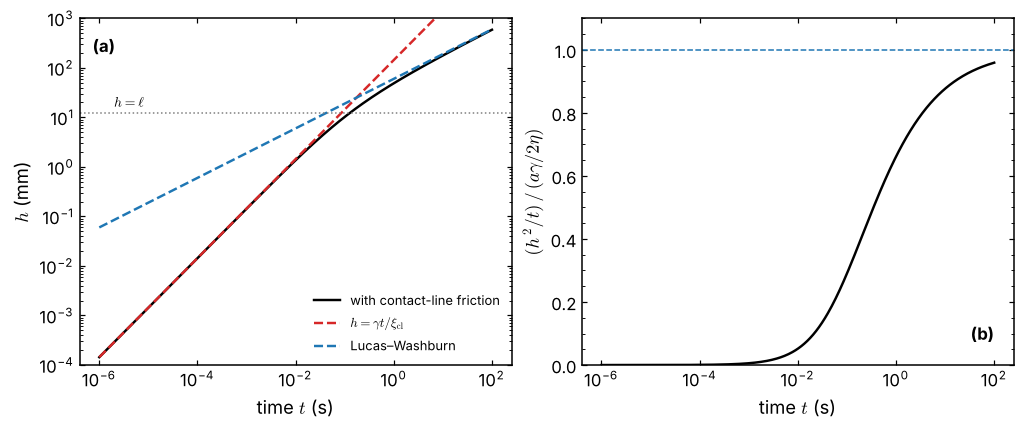

ell = 12.50 mm for a = 0.1 mm, water, xi_cl = 0.5 Pa s


In [5]:
h, hdot = sp.symbols("h hdot")
a, gam, ct, eta, xi = sp.symbols("a gamma cos_theta eta xi_cl", positive=True)
eq = on.kinetic_equations(-2 * sp.pi * a * gam * ct * h,
                          4 * sp.pi * eta * h * hdot**2 + sp.Rational(1, 2) * xi * 2 * sp.pi * a * hdot**2, [h], [hdot])
print("hdot =", sp.factor(eq[hdot]))
tt = sp.symbols("t", positive=True)
ell = a * xi / (4 * eta)
h_exact = sp.sqrt(ell**2 + a * gam * ct * tt / (2 * eta)) - ell
print("residual of the exact solution:", sp.simplify(sp.diff(h_exact, tt) - eq[hdot].subs(h, h_exact)))

vals = {a: 1e-4, gam: 0.072, ct: 1.0, eta: 1e-3, xi: 0.5}
ell_v = float(ell.subs(vals))
h_num = sp.lambdify(tt, h_exact.subs(vals), "numpy")
t = np.logspace(-6, 2, 400)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.8))
ax1.loglog(t, 1e3 * h_num(t), "k-", label="with contact-line friction")
ax1.loglog(t, 1e3 * float(vals[gam] / vals[xi]) * t, "--", color="C3", label=r"$h = \gamma t/\xi_{\rm cl}$")
ax1.loglog(t, 1e3 * np.sqrt(vals[a] * vals[gam] * t / (2 * vals[eta])), "--", color="C0", label="Lucas–Washburn")
ax1.axhline(1e3 * ell_v, color="0.5", ls=":", lw=1); ax1.text(2e-6, 1e3 * ell_v * 1.3, r"$h = \ell$", fontsize=9)
ax1.set_xlabel("time $t$ (s)"); ax1.set_ylabel("$h$ (mm)"); ax1.set_ylim(1e-4, 1e3); ax1.legend(loc="lower right", fontsize=8.5)
on.panel_label(ax1, "(a)")
ax2.semilogx(t, h_num(t) ** 2 / t / (vals[a] * vals[gam] / (2 * vals[eta])), "k-")
ax2.axhline(1, color="C0", ls="--", lw=1)
ax2.set_xlabel("time $t$ (s)"); ax2.set_ylabel(r"$(h^2/t)\,/\,(a\gamma/2\eta)$"); ax2.set_ylim(0, 1.1)
on.panel_label(ax2, "(b)", x=0.9, y=0.12)
plt.show()
print(f"ell = {1e3 * ell_v:.2f} mm for a = 0.1 mm, water, xi_cl = 0.5 Pa s")

**(a)** Rise in a horizontal tube with contact-line friction (water, $a = 0.1$ mm,
$\xi_{\rm cl} = 0.5$ Pa s, an illustrative value): linear at first, Lucas–Washburn once
the column is much longer than $\ell$. **(b)** The ratio $h^2/t$ approaches the Washburn
value only slowly.